# Set the map area of each chart

This notebook makes the chart table `configs/charts.csv` and saves the map area of each chart.

**Work order:**
1. Run Cells 1 to 3 one time.
2. For each chart, run Cell 4 and Cell 5 with the chart name.
3. Run Cell 6 to see the remaining charts.

## Cell 1: Imports and settings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

CHART_DIR = "../data/raw/charts"
TABLE = "../configs/charts.csv"   # Outside data/, so Git saves it.
SCALE = 10                        # The small image is 1/10 of the real size.

TEST = ["Denver", "Miami", "Seattle"]
VAL = ["Charlotte", "Chicago", "Phoenix"]

## Cell 2: Make the chart table

Check the output: 34 charts, 28 train, 3 val, and 3 test.

In [2]:
os.makedirs("../configs", exist_ok=True)

# Make the table only one time. This prevents the loss of the limits that you already wrote.
if not os.path.exists(TABLE):
    files = sorted(f for f in os.listdir(CHART_DIR) if f.endswith(".tif"))
    rows = []
    for f in files:
        name = f.replace(" SEC.tif", "")
        split = "test" if name in TEST else "val" if name in VAL else "train"
        # The limits start at 0. You set them in Cell 5.
        rows.append({"chart": name, "tif_file": f, "row_min": 0, "row_max": 0, "col_min": 0, "col_max": 0, "split": split})
    pd.DataFrame(rows).to_csv(TABLE, index=False)

charts = pd.read_csv(TABLE)
print(len(charts), "charts")
print(charts["split"].value_counts())
charts

34 charts
split
train    28
val       3
test      3
Name: count, dtype: int64


,chart,tif_file,row_min,row_max,col_min,col_max,split
0,Albuquerque,Albuquerque SEC.tif,0,11000,2700,17700,train
1,Atlanta,Atlanta SEC.tif,0,0,0,0,train
2,Billings,Billings SEC.tif,0,0,0,0,train
3,Brownsville,Brownsville SEC.tif,0,0,0,0,train
4,Charlotte,Charlotte SEC.tif,0,0,0,0,val
5,Cheyenne,Cheyenne SEC.tif,0,0,0,0,train
6,Chicago,Chicago SEC.tif,0,0,0,0,val
7,Cincinnati,Cincinnati SEC.tif,0,0,0,0,train
8,Dallas-Ft Worth,Dallas-Ft Worth SEC.tif,0,0,0,0,train
9,Denver,Denver SEC.tif,0,0,0,0,test


## Cell 3: Functions to show a chart and save its map area

In [3]:
def load_small(name):
    # Open the chart, read it at 1/10 size, and convert the color indexes to RGB.
    f = charts.loc[charts["chart"] == name, "tif_file"].iloc[0]
    with rasterio.open(os.path.join(CHART_DIR, f)) as src:
        small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))
        lut = np.zeros((256, 3), dtype=np.uint8)
        for index, color in src.colormap(1).items():
            lut[index] = color[:3]
    return lut[small]


def show(name, box=None):
    # Show the small chart. If you give a box, draw it as a red rectangle.
    img = load_small(name)
    plt.figure(figsize=(16, 10))
    plt.imshow(img)
    if box:
        r0, r1, c0, c1 = box
        plt.gca().add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor="red", linewidth=2))
    plt.title(name)
    plt.show()


def set_area(name, r0, r1, c0, c1):
    # Give the limits as you read them on the small image axes.
    # The function draws the rectangle, multiplies the values by 10, and saves them in the table.
    show(name, (r0, r1, c0, c1))
    i = charts.index[charts["chart"] == name][0]
    charts.loc[i, ["row_min", "row_max", "col_min", "col_max"]] = [r0 * SCALE, r1 * SCALE, c0 * SCALE, c1 * SCALE]
    charts.to_csv(TABLE, index=False)

## Cell 4: Show one chart

Read the top, bottom, left, and right edges of the main map on the axes. Do not multiply them.
Keep the legend panels, the insets, and the areas of Canada and Mexico outside the map area.

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_47562/3047784643.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))


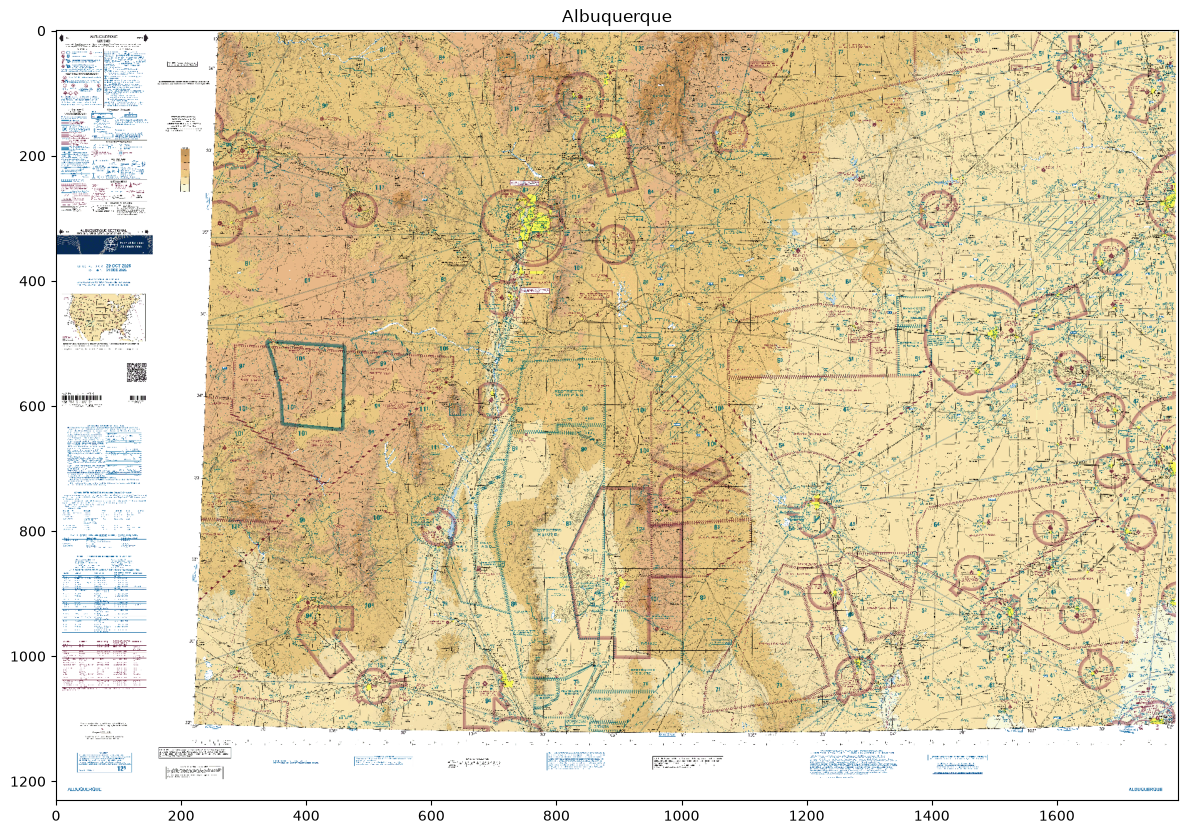

In [4]:
show("Albuquerque")

## Cell 5: Save the map area of that chart

Order: top row, bottom row, left column, right column. Use the values from the axes.
The values below are only an example. If the red rectangle is not correct, change the values and run the cell again. The new values replace the old values.

Los Angeles (already checked): `set_area("Los Angeles", 150, 1050, 470, 1650)`

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_47562/3047784643.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))


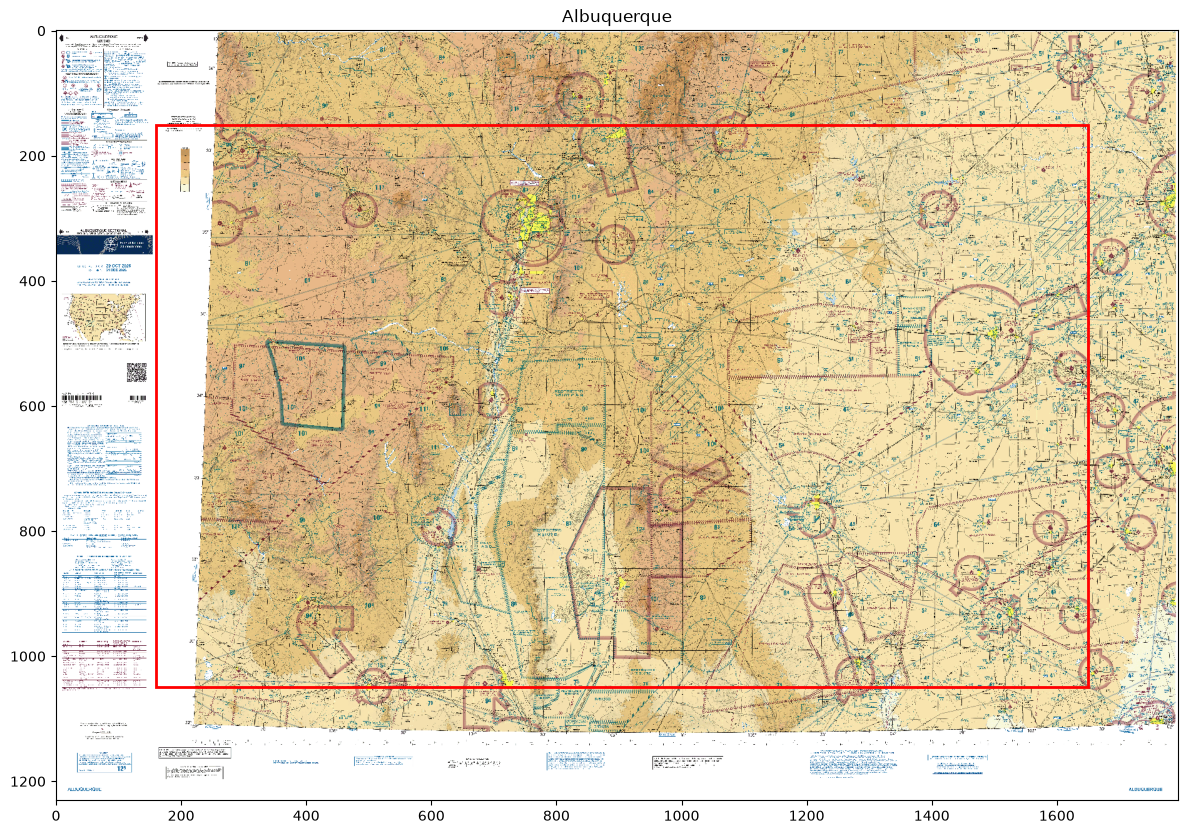

In [5]:
set_area("Albuquerque", 150, 1050, 160, 1650)

## Cell 6: See which charts are not done

In [6]:
todo = charts[charts["row_max"] == 0]["chart"].tolist()
print(len(todo), "charts not done:")
print(todo)

33 charts not done:
['Atlanta', 'Billings', 'Brownsville', 'Charlotte', 'Cheyenne', 'Chicago', 'Cincinnati', 'Dallas-Ft Worth', 'Denver', 'Detroit', 'El Paso', 'Great Falls', 'Green Bay', 'Houston', 'Jacksonville', 'Kansas City', 'Klamath Falls', 'Las Vegas', 'Los Angeles', 'Memphis', 'Miami', 'New Orleans', 'New York', 'Omaha', 'Phoenix', 'Salt Lake City', 'San Antonio', 'San Francisco', 'Seattle', 'St Louis', 'Twin Cities', 'Washington', 'Wichita']
